# Delhi AQI — 10-Day Ahead Forecasting & Explainability
This notebook uses the uploaded **`delhi_aqi_features.csv`** as the source dataset.

### Goals
1. Perform additional EDA on the engineered features.
2. Convert the hourly engineered dataset into a **daily station-level forecasting dataset**.
3. Forecast AQI **1–10 days ahead**.
4. Compare:
   - Persistence / seasonal-naive baselines
   - **SARIMAX**
   - **VARIMA-style multivariate model**
   - **XGBoost direct multi-horizon models**
5. Produce interpretable feature importance and **SHAP** explanations.
6. Group SHAP values into meaningful families such as:
   - AQI history
   - PM2.5 history
   - PM10 history
   - NO2 history
   - weather
   - calendar
7. Produce a final 10-day forecast table and plots.

> **Important modeling principle:** every feature used to predict day `t+h` must be information available at or before day `t`. The notebook therefore uses lagged/rolling features and a chronological train/test split.

> **Interpretability note:** SHAP answers *which input features drove the model prediction*. It does **not** prove that a pollutant causally caused AQI. The uploaded feature dataset contains pollutant history (`*_lag_*`) rather than the original contemporaneous pollutant columns, so pollutant contribution here means contribution of **historical pollutant signals to the forecast**.


## 0. Imports and configuration

The notebook is deliberately configuration-driven so you can change the forecast horizon, test period, target aggregation, station, and model settings without rewriting the pipeline.


In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR

import shap

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

# ---------------- CONFIG ----------------
DATA_PATH = Path("delhi_aqi_features.csv")

FORECAST_HORIZON = 10
TEST_DAYS = 180

DAILY_AQI_AGG = "mean"
CLASSICAL_SERIES = "Delhi_mean"

RANDOM_STATE = 42

## 1. Load and validate the uploaded dataset

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

print("Shape:", df.shape)
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Stations:", df["station"].unique().tolist())
print("\nDtypes:")
display(df.dtypes.to_frame("dtype").T)

# Basic uniqueness checks
print("Duplicate station/timestamp rows:",
      df.duplicated(["station", "timestamp"]).sum())

print("\nAQI availability:")
display(
    df.groupby("station")["AQI"]
      .agg(["count", "mean", "min", "max"])
      .round(2)
)

print("\nMissingness:")
display(
    (df.isna().mean() * 100).sort_values(ascending=False).round(2).to_frame("missing_%")
)


Shape: (175320, 106)
Date range: 2022-01-01 00:00:00 to 2025-12-31 23:00:00
Stations: ['Anand Vihar', 'Dwarka Sector 8', 'IMD Lodhi Road', 'ITO', 'Punjabi Bagh']

Dtypes:


,station,timestamp,AQI,AQI_Bucket,hour,dayofweek,day,month,is_weekend,season,is_pollution_season,is_stubble_season,hour_of_week,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,how_sin,how_cos,PM25,PM10,NO2,SO2,CO,O3,NH3,AQI_lag_1d,AQI_lag_2d,AQI_lag_3d,AQI_lag_7d,AQI_lag_15d,AQI_lag_30d,PM25_lag_1d,PM25_lag_2d,PM25_lag_3d,PM25_lag_7d,PM25_lag_15d,PM25_lag_30d,PM10_lag_1d,PM10_lag_2d,PM10_lag_3d,PM10_lag_7d,PM10_lag_15d,PM10_lag_30d,NO2_lag_1d,NO2_lag_2d,NO2_lag_3d,NO2_lag_7d,NO2_lag_15d,NO2_lag_30d,AQI_roll_mean_3d,AQI_roll_mean_7d,AQI_roll_mean_15d,AQI_roll_mean_30d,AQI_roll_std_3d,AQI_roll_std_7d,AQI_roll_std_15d,AQI_roll_std_30d,AQI_roll_min_3d,AQI_roll_min_7d,AQI_roll_min_15d,AQI_roll_min_30d,AQI_roll_max_3d,AQI_roll_max_7d,AQI_roll_max_15d,AQI_roll_max_30d,PM25_roll_mean_3d,PM25_roll_mean_7d,PM25_roll_mean_15d,PM25_roll_mean_30d,PM25_roll_std_3d,PM25_roll_std_7d,PM25_roll_std_15d,PM25_roll_std_30d,PM25_roll_min_3d,PM25_roll_min_7d,PM25_roll_min_15d,PM25_roll_min_30d,PM25_roll_max_3d,PM25_roll_max_7d,PM25_roll_max_15d,PM25_roll_max_30d,AQI_diff_1d,AQI_diff_7d,PM25_diff_1d,PM25_diff_7d,NO2_diff_1d,NO2_diff_7d,temperature_lag_1d,humidity_lag_1d,wind_speed_lag_1d,pressure_lag_1d,solar_radiation_lag_1d,temperature_roll_mean_1d,humidity_roll_mean_1d,wind_speed_roll_mean_1d,pressure_roll_mean_1d,solar_radiation_roll_mean_1d,temperature,humidity,wind_speed,pressure,solar_radiation,total_rainfall
dtype,str,datetime64[us],float64,str,int64,int64,int64,int64,int64,str,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


Duplicate station/timestamp rows: 0

AQI availability:


,count,mean,min,max
station,,,,
Anand Vihar,32266,272.49,34.47,500.0
Dwarka Sector 8,34593,228.57,16.12,500.0
IMD Lodhi Road,33118,173.35,8.37,500.0
ITO,33416,202.97,36.21,500.0
Punjabi Bagh,34078,226.29,25.31,500.0



Missingness:


,missing_%
pressure_lag_1d,53.45
pressure,53.42
pressure_roll_mean_1d,52.71
wind_speed_lag_1d,42.16
wind_speed,42.12
...,...
dayofweek,0.00
day,0.00
month,0.00
is_weekend,0.00


## 2. Additional EDA

The dataset already contains engineered lags, rolling statistics, calendar variables, weather variables, and the AQI target. The EDA below focuses on:

- station-level AQI behavior
- seasonality
- extreme pollution events
- rolling volatility
- feature correlation
- missingness
- relationships between AQI history and weather


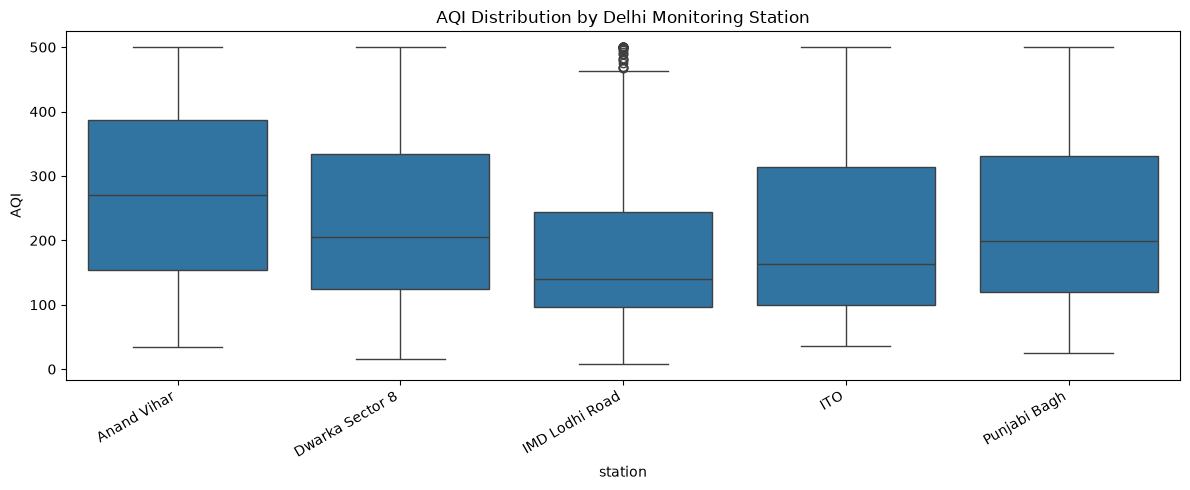

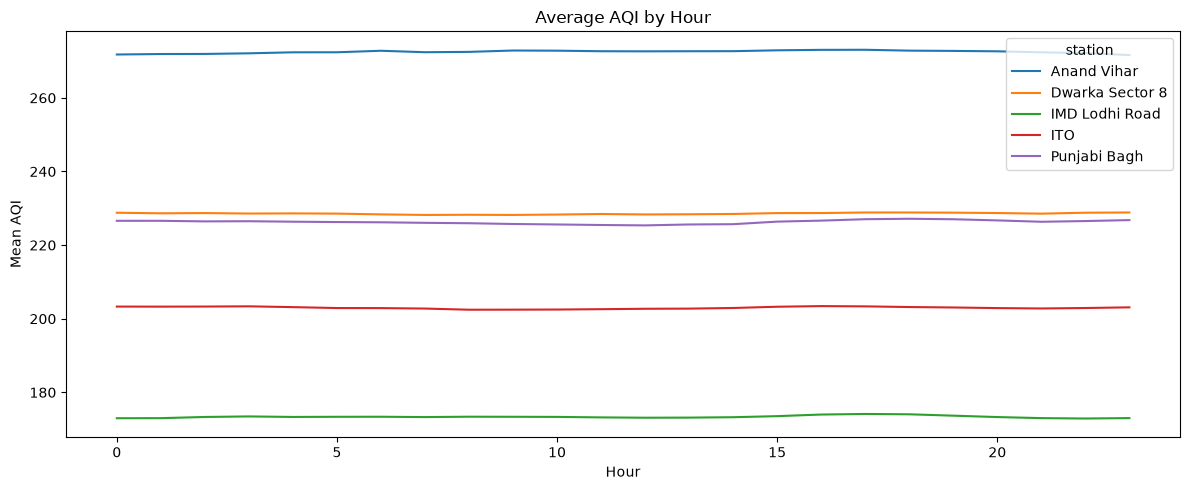

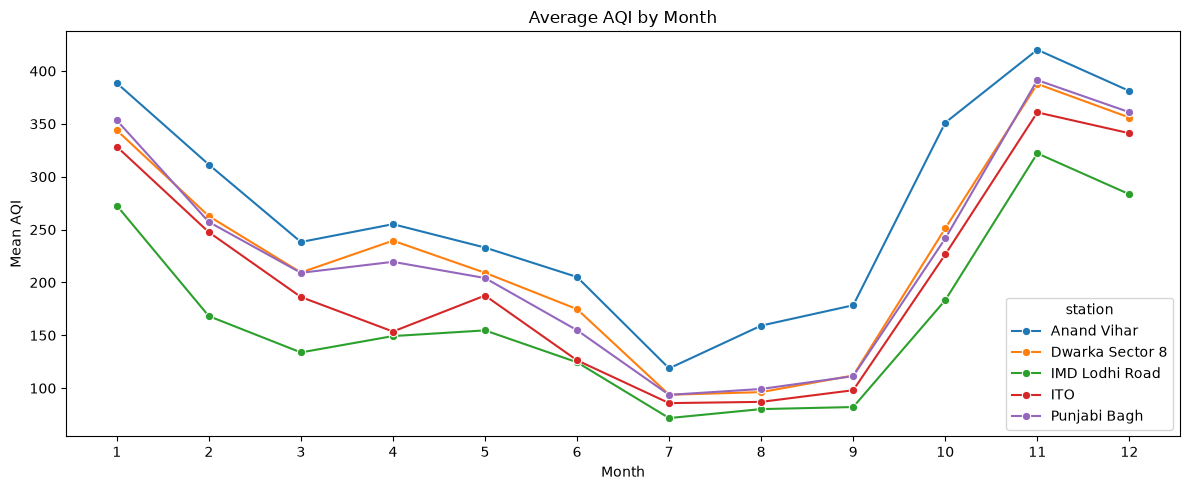

AQI_Bucket,Good,Moderate,Poor,Satisfactory,Severe,Very Poor
station,,,,,,
Anand Vihar,0.35,29.31,16.64,7.88,22.83,22.99
Dwarka Sector 8,2.04,34.29,16.86,12.54,9.76,24.51
IMD Lodhi Road,4.52,42.13,11.79,21.86,1.36,18.36
ITO,1.00,32.24,12.71,23.96,6.65,23.45
Punjabi Bagh,0.98,36.24,14.35,13.14,10.43,24.85


,high,very_high,hazardous
station,,,
Anand Vihar,57.47,42.16,21.01
Dwarka Sector 8,50.45,33.81,9.63
IMD Lodhi Road,29.75,18.62,1.28
ITO,40.79,28.68,6.33
Punjabi Bagh,48.26,34.30,10.14


In [3]:
# 2.1 AQI distribution by station
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="station", y="AQI")
plt.xticks(rotation=30, ha="right")
plt.title("AQI Distribution by Delhi Monitoring Station")
plt.tight_layout()
plt.show()

# 2.2 Hour-of-day pattern
hourly_profile = (
    df.groupby(["station", "hour"])["AQI"].mean().reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly_profile, x="hour", y="AQI", hue="station")
plt.title("Average AQI by Hour")
plt.xlabel("Hour")
plt.ylabel("Mean AQI")
plt.tight_layout()
plt.show()

# 2.3 Month/season pattern
monthly_profile = (
    df.groupby(["station", "month"])["AQI"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_profile, x="month", y="AQI", hue="station", marker="o")
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# 2.4 AQI category proportions
if "AQI_Bucket" in df.columns:
    bucket_share = pd.crosstab(
        df["station"], df["AQI_Bucket"], normalize="index")*100
    display(bucket_share.round(2))

# 2.5 Extreme AQI frequency
extreme = (
    df.assign(
        hazardous=df["AQI"] >= 400,
        very_high=df["AQI"] >= 300,
        high=df["AQI"] >= 200
    ).groupby("station")[["high", "very_high", "hazardous"]].mean() * 100
)
display(extreme.round(2))


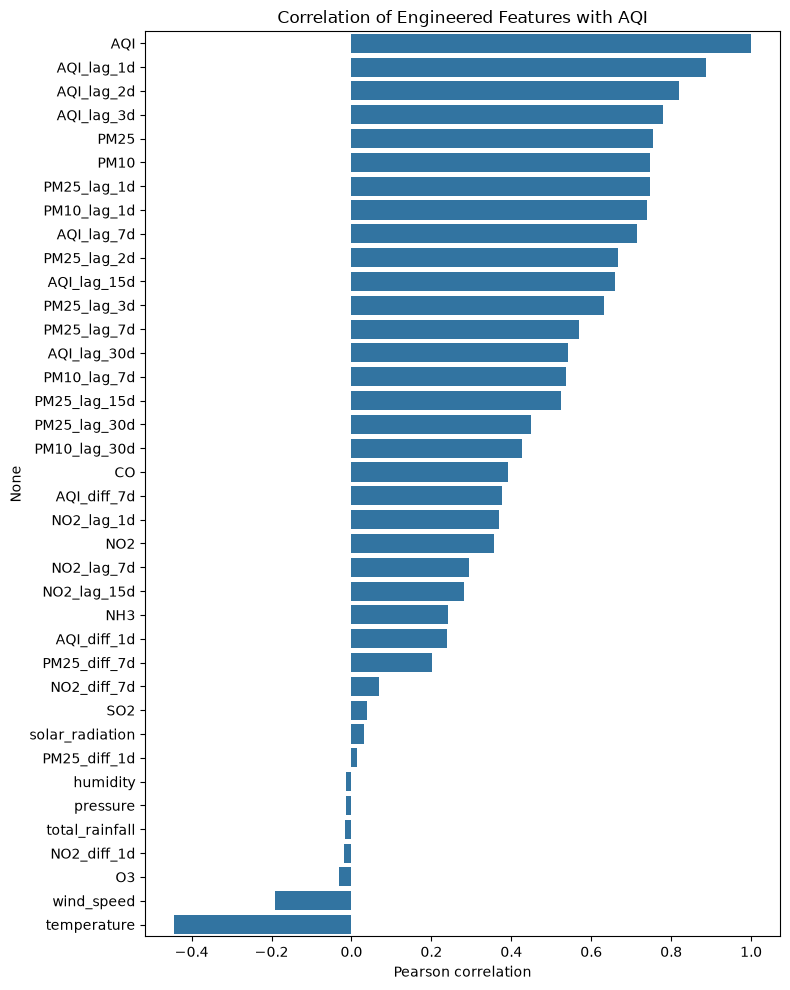

,corr_with_AQI
AQI,1.000
AQI_lag_1d,0.886
AQI_lag_2d,0.819
AQI_lag_3d,0.780
PM25,0.755
PM10,0.746
PM25_lag_1d,0.746
PM10_lag_1d,0.739
AQI_lag_7d,0.715
PM25_lag_2d,0.666


In [4]:
# 2.6 Correlation of the most useful engineered predictors with AQI
candidate = [
    "AQI", "AQI_lag_1d", "AQI_lag_2d", "AQI_lag_3d", "AQI_lag_7d",
    "AQI_lag_15d", "AQI_lag_30d",
    'PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3',
    "PM25_lag_1d", "PM25_lag_2d", "PM25_lag_3d", "PM25_lag_7d",
    "PM25_lag_15d", "PM25_lag_30d",
    "PM10_lag_1d", "PM10_lag_7d", "PM10_lag_30d",
    "NO2_lag_1d", "NO2_lag_7d", "NO2_lag_15d",
    "temperature", "humidity", "wind_speed", "pressure",
    "solar_radiation", "total_rainfall",
    "AQI_diff_1d", "AQI_diff_7d",
    "PM25_diff_1d", "PM25_diff_7d",
    "NO2_diff_1d", "NO2_diff_7d"
]
candidate = [c for c in candidate if c in df.columns]

corr = df[candidate].corr(numeric_only=True)["AQI"].sort_values(ascending=False)

plt.figure(figsize=(8, 10))
sns.barplot(x=corr.values, y=corr.index)
plt.title("Correlation of Engineered Features with AQI")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

display(corr.round(3).to_frame("corr_with_AQI"))


## 3. Create the daily forecasting dataset

The uploaded file is hourly. For a **10-day ahead** forecast, the main forecasting table should be daily.

### Target definition

The notebook defaults to:

`daily_AQI = mean(hourly AQI available during that day)`

This is a modeling target based on the AQI already present in the uploaded feature dataset. If your project documentation defines daily AQI differently, change `DAILY_AQI_AGG`.

For the ML models, we then create:

- `target_h1` = AQI 1 day ahead
- ...
- `target_h10` = AQI 10 days ahead

This is a **direct multi-horizon** setup: one model per horizon. It avoids recursive error accumulation.


In [5]:
# Helper: aggregate hourly engineered data to daily station-level data.
df["date"] = df["timestamp"].dt.floor("D")

# Columns that should be averaged/summarized at daily level.
mean_cols = [
    "AQI",
    "temperature", "humidity", "wind_speed", "pressure",
    "solar_radiation", "total_rainfall",
    "AQI_lag_1d", "AQI_lag_2d", "AQI_lag_3d", "AQI_lag_7d",
    "AQI_lag_15d", "AQI_lag_30d",
    'PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3',
    "PM25_lag_1d", "PM25_lag_2d", "PM25_lag_3d", "PM25_lag_7d",
    "PM25_lag_15d", "PM25_lag_30d",
    "PM10_lag_1d", "PM10_lag_2d", "PM10_lag_3d", "PM10_lag_7d",
    "PM10_lag_15d", "PM10_lag_30d",
    "NO2_lag_1d", "NO2_lag_2d", "NO2_lag_3d", "NO2_lag_7d",
    "NO2_lag_15d",
    "AQI_roll_mean_3d", "AQI_roll_mean_7d", "AQI_roll_mean_15d", "AQI_roll_mean_30d",
    "AQI_roll_std_3d", "AQI_roll_std_7d", "AQI_roll_std_15d", "AQI_roll_std_30d",
    "AQI_roll_min_3d", "AQI_roll_min_7d", "AQI_roll_min_15d", "AQI_roll_min_30d",
    "AQI_roll_max_3d", "AQI_roll_max_7d", "AQI_roll_max_15d", "AQI_roll_max_30d",
    "PM25_roll_mean_3d", "PM25_roll_mean_7d", "PM25_roll_mean_15d", "PM25_roll_mean_30d",
    "PM25_roll_std_3d", "PM25_roll_std_7d", "PM25_roll_std_15d", "PM25_roll_std_30d",
    "PM25_roll_min_3d", "PM25_roll_min_7d", "PM25_roll_min_15d", "PM25_roll_min_30d",
    "PM25_roll_max_3d", "PM25_roll_max_7d", "PM25_roll_max_15d", "PM25_roll_max_30d",
    "AQI_diff_1d", "AQI_diff_7d", "PM25_diff_1d", "PM25_diff_7d",
    "NO2_diff_1d", "NO2_diff_7d",
    "temperature_lag_1d", "humidity_lag_1d", "wind_speed_lag_1d",
    "pressure_lag_1d", "solar_radiation_lag_1d",
    "temperature_roll_mean_1d", "humidity_roll_mean_1d",
    "wind_speed_roll_mean_1d", "pressure_roll_mean_1d",
    "solar_radiation_roll_mean_1d"
]
mean_cols = [c for c in mean_cols if c in df.columns]

daily = (
    df.groupby(["station", "date"], as_index=False)[mean_cols]
      .mean()
)

# Add daily calendar features from the date itself.
daily["dayofweek"] = daily["date"].dt.dayofweek
daily["day"] = daily["date"].dt.day
daily["month"] = daily["date"].dt.month
daily["dayofyear"] = daily["date"].dt.dayofyear
daily["is_weekend"] = (daily["dayofweek"] >= 5).astype(int)

# General annual cyclic encoding.
daily["doy_sin"] = np.sin(2 * np.pi * daily["dayofyear"] / 365.25)
daily["doy_cos"] = np.cos(2 * np.pi * daily["dayofyear"] / 365.25)

# Weekly cyclic encoding.
daily["dow_sin"] = np.sin(2 * np.pi * daily["dayofweek"] / 7)
daily["dow_cos"] = np.cos(2 * np.pi * daily["dayofweek"] / 7)

# Add station-level daily AQI lags from the daily target itself.
daily = daily.sort_values(["station", "date"]).reset_index(drop=True)

for lag in [1, 2, 3, 7, 14, 30]:
    daily[f"daily_AQI_lag_{lag}d"] = (
        daily.groupby("station")["AQI"].shift(lag)
    )

# Daily rolling features must use ONLY previous days.
for w in [3, 7, 14, 30]:
    daily[f"daily_AQI_roll_mean_{w}d"] = (
        daily.groupby("station")["AQI"]
             .transform(lambda s: s.shift(1).rolling(w, min_periods=max(2, w//2)).mean())
    )
    daily[f"daily_AQI_roll_std_{w}d"] = (
        daily.groupby("station")["AQI"]
             .transform(lambda s: s.shift(1).rolling(w, min_periods=max(2, w//2)).std())
    )

daily["daily_AQI_diff_1d"] = (
    daily["daily_AQI_lag_1d"] - daily["daily_AQI_lag_2d"]
)
daily["daily_AQI_diff_7d"] = (
    daily["daily_AQI_lag_1d"] - daily["daily_AQI_lag_7d"]
)

# Direct 1–10 day targets.
for h in range(1, FORECAST_HORIZON + 1):
    daily[f"target_h{h}"] = (
        daily.groupby("station")["AQI"].shift(-h)
    )

print("Daily shape:", daily.shape)
display(daily.head())


Daily shape: (7305, 122)


,station,date,AQI,temperature,humidity,wind_speed,pressure,solar_radiation,total_rainfall,AQI_lag_1d,AQI_lag_2d,AQI_lag_3d,AQI_lag_7d,AQI_lag_15d,AQI_lag_30d,PM25,PM10,NO2,SO2,CO,O3,NH3,PM25_lag_1d,PM25_lag_2d,PM25_lag_3d,PM25_lag_7d,PM25_lag_15d,PM25_lag_30d,PM10_lag_1d,PM10_lag_2d,PM10_lag_3d,PM10_lag_7d,PM10_lag_15d,PM10_lag_30d,NO2_lag_1d,NO2_lag_2d,NO2_lag_3d,NO2_lag_7d,NO2_lag_15d,AQI_roll_mean_3d,AQI_roll_mean_7d,AQI_roll_mean_15d,AQI_roll_mean_30d,AQI_roll_std_3d,AQI_roll_std_7d,AQI_roll_std_15d,AQI_roll_std_30d,AQI_roll_min_3d,AQI_roll_min_7d,AQI_roll_min_15d,AQI_roll_min_30d,AQI_roll_max_3d,AQI_roll_max_7d,AQI_roll_max_15d,AQI_roll_max_30d,PM25_roll_mean_3d,PM25_roll_mean_7d,PM25_roll_mean_15d,PM25_roll_mean_30d,PM25_roll_std_3d,...,PM25_roll_std_30d,PM25_roll_min_3d,PM25_roll_min_7d,PM25_roll_min_15d,PM25_roll_min_30d,PM25_roll_max_3d,PM25_roll_max_7d,PM25_roll_max_15d,PM25_roll_max_30d,AQI_diff_1d,AQI_diff_7d,PM25_diff_1d,PM25_diff_7d,NO2_diff_1d,NO2_diff_7d,temperature_lag_1d,humidity_lag_1d,wind_speed_lag_1d,pressure_lag_1d,solar_radiation_lag_1d,temperature_roll_mean_1d,humidity_roll_mean_1d,wind_speed_roll_mean_1d,pressure_roll_mean_1d,solar_radiation_roll_mean_1d,dayofweek,day,month,dayofyear,is_weekend,doy_sin,doy_cos,dow_sin,dow_cos,daily_AQI_lag_1d,daily_AQI_lag_2d,daily_AQI_lag_3d,daily_AQI_lag_7d,daily_AQI_lag_14d,daily_AQI_lag_30d,daily_AQI_roll_mean_3d,daily_AQI_roll_std_3d,daily_AQI_roll_mean_7d,daily_AQI_roll_std_7d,daily_AQI_roll_mean_14d,daily_AQI_roll_std_14d,daily_AQI_roll_mean_30d,daily_AQI_roll_std_30d,daily_AQI_diff_1d,daily_AQI_diff_7d,target_h1,target_h2,target_h3,target_h4,target_h5,target_h6,target_h7,target_h8,target_h9,target_h10
0,Anand Vihar,2022-01-01,495.313194,13.965000,75.319167,0.317500,974.072083,157.485833,0.0,NaN,NaN,NaN,NaN,NaN,NaN,393.562500,610.277778,98.511250,21.031250,3.303333,9.339583,45.737000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,485.669674,489.648377,493.308748,NaN,20.315917,20.315917,16.735197,NaN,457.818750,457.818750,457.818750,NaN,494.727344,500.0,500.0,NaN,484.573180,478.724234,451.733323,405.273229,153.246093,...,185.671970,318.967391,305.590909,257.013158,208.267857,728.750000,734.000000,739.000000,739.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.219577,79.007877,0.318152,974.203247,158.634027,5,1,1,1,1,0.017202,0.999852,-0.974928,-0.222521,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,500.000000,495.491115,498.800532,488.401272,360.516506,199.236111,109.175596,78.869821,197.018732,321.496394
1,Anand Vihar,2022-01-02,500.000000,14.334167,75.317500,0.316250,974.162917,153.106250,0.0,495.313194,NaN,NaN,NaN,NaN,NaN,424.812500,610.650000,96.325833,29.270417,1.972917,11.391250,43.763333,393.562500,NaN,NaN,NaN,NaN,NaN,610.277778,NaN,NaN,NaN,NaN,NaN,98.511250,NaN,NaN,NaN,NaN,497.643759,497.643759,497.643759,497.745088,9.789698,9.789698,9.789698,9.604014,457.818750,457.818750,457.818750,457.818750,500.000000,500.0,500.0,500.0,420.790374,420.790374,420.790374,420.790374,196.779251,...,196.779251,159.260417,159.260417,159.260417,159.260417,816.864583,816.864583,816.864583,816.864583,4.686806,NaN,31.250000,NaN,-2.185417,NaN,13.965000,75.319167,0.317500,974.072083,157.485833,14.123212,76.243628,0.316458,974.247257,154.991701,6,2,1,2,1,0.034398,0.999408,-0.781831,0.623490,495.313194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,495.491115,498.800532,488.401272,360.516506,199.236111,109.175596,78.869821,197.018732,321.496394,321.874750
2,Anand Vihar,2022-01-03,495.491115,14.827917,72.187917,0.349167,973.684167,153.843750,0.0,500.000000,495.313194,NaN,NaN,NaN,NaN,367.697917,656.152174,109.210417,18.565833,2.411667,8.335833,45.436667,424.812500,393.562500,NaN,NaN,NaN,NaN,610.650000,610.277778,NaN,NaN,NaN,NaN,96.325833,98.511250,NaN,NaN,NaN,497.797344,497.797344,497.797344,497.797344,6.976294,6.976294,6.976294,6.976294,457.818750,457.818750,457.818750,457.818750,500.000000,500.0,500.0,500.0,412.386917,412.386

## 4. Leakage checks

This section checks that the forecasting features do not directly contain future AQI.

The direct targets are shifted **backward** (`shift(-h)`), while all history features are shifted **backward in the feature construction** so they contain past information only.

For a real deployment, do not feed future observed weather/pollutants into the model. If future weather is used, it must come from a forecast available at prediction time.


In [6]:
# Drop rows that do not have the minimum history/target needed for the longest horizon.
feature_cols_check = [
    c for c in daily.columns
    if c.startswith("daily_AQI_lag_") or c.startswith("daily_AQI_roll_")
]

print("Longest history feature:", [c for c in feature_cols_check if "30" in c][:3])
print("Target availability:")
display(
    daily[[f"target_h{h}" for h in range(1, FORECAST_HORIZON + 1)]]
    .notna().mean().round(3).to_frame("available_fraction")
)

# Simple chronological split
cutoff = daily["date"].max() - pd.Timedelta(days=TEST_DAYS)
train_mask = daily["date"] < cutoff
test_mask = daily["date"] >= cutoff

print("Train through:", daily.loc[train_mask, "date"].max())
print("Test from:", daily.loc[test_mask, "date"].min())
print("Test cutoff:", cutoff)


Longest history feature: ['daily_AQI_lag_30d', 'daily_AQI_roll_mean_30d', 'daily_AQI_roll_std_30d']
Target availability:


,available_fraction
target_h1,0.969
target_h2,0.968
target_h3,0.968
target_h4,0.967
target_h5,0.966
target_h6,0.966
target_h7,0.965
target_h8,0.964
target_h9,0.964
target_h10,0.963


Train through: 2025-07-03 00:00:00
Test from: 2025-07-04 00:00:00
Test cutoff: 2025-07-04 00:00:00


## 5. Baselines

Before sophisticated models, compare against two strong baselines:

1. **Persistence:** tomorrow's AQI = today's AQI.
2. **7-day seasonal naive:** tomorrow's AQI = AQI 7 days ago.

A complex model that cannot beat these baselines is not useful.


In [7]:
def evaluate(y_true, y_pred):
    mask = pd.notna(y_true) & pd.notna(y_pred)
    y_true = np.asarray(y_true)[mask]
    y_pred = np.asarray(y_pred)[mask]
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_results = []

for h in range(1, FORECAST_HORIZON + 1):
    target = f"target_h{h}"

    # At day t, predict t+h using t's observed AQI.
    pred_persistence = daily["AQI"]
    pred_seasonal = daily["daily_AQI_lag_7d"]  # AQI(t-7)

    m1 = test_mask & daily[target].notna() & daily["AQI"].notna()
    m2 = test_mask & daily[target].notna() & daily["daily_AQI_lag_7d"].notna()

    r1 = evaluate(daily.loc[m1, target], pred_persistence.loc[m1])
    r2 = evaluate(daily.loc[m2, target], pred_seasonal.loc[m2])

    baseline_results.extend([
        {"model": "Persistence", "horizon": h, **r1},
        {"model": "7-day seasonal naive", "horizon": h, **r2}
    ])

baseline_results = pd.DataFrame(baseline_results)
display(baseline_results)


,model,horizon,MAE,RMSE,R2
0,Persistence,1,25.438471,36.594668,0.932597
1,7-day seasonal naive,1,46.360852,70.702095,0.747675
2,Persistence,2,35.994998,50.226565,0.872819
3,7-day seasonal naive,2,49.462349,74.697547,0.718287
4,Persistence,3,39.737392,56.221476,0.840147
5,7-day seasonal naive,3,53.272521,79.631088,0.679547
6,Persistence,4,41.996017,59.823740,0.818019
7,7-day seasonal naive,4,56.765540,83.547389,0.646911
8,Persistence,5,44.056213,62.678817,0.799667
9,7-day seasonal naive,5,58.876069,86.261895,0.622924


# 6. XGBoost — direct 1-to-10 day forecasting

For each horizon `h`, a separate XGBoost model is trained:

`X(t) → AQI(t+h)`

This is preferable to recursively feeding predictions back into the model when the goal is a 10-day forecast because recursive forecasting can accumulate errors.

### Feature groups

- AQI history
- pollutant history: PM2.5, PM10, NO2
- rolling/trend features
- weather history
- calendar/cyclic features
- station identity

The notebook automatically discovers available columns rather than assuming raw pollutant columns exist.


In [8]:
# Build feature groups from the columns actually present.
calendar_features = [
    c for c in [
        "dayofweek", "day", "month", "dayofyear", "is_weekend",
        "doy_sin", "doy_cos", "dow_sin", "dow_cos",
        "is_pollution_season", "is_stubble_season"
    ] if c in daily.columns
]

aqi_features = [
    c for c in daily.columns
    if (
        c.startswith("AQI_lag_")
        or c.startswith("AQI_roll_")
        or c.startswith("AQI_diff_")
        or c.startswith("daily_AQI_lag_")
        or c.startswith("daily_AQI_roll_")
        or c.startswith("daily_AQI_diff_")
    )
]

current_pollutant_features = [c for c in ['PM25', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3']]

historical_pollutant_features = [c for c in daily.columns
    if any(c.startswith(prefix) for prefix in ["PM25_", "PM10_", "NO2_"])]
                                                                         

weather_features = [
    c for c in [
        "temperature", "humidity", "wind_speed", "pressure",
        "solar_radiation", "total_rainfall",
        "temperature_lag_1d", "humidity_lag_1d",
        "wind_speed_lag_1d", "pressure_lag_1d",
        "solar_radiation_lag_1d",
        "temperature_roll_mean_1d",
        "humidity_roll_mean_1d",
        "wind_speed_roll_mean_1d",
        "pressure_roll_mean_1d",
        "solar_radiation_roll_mean_1d"
    ] if c in daily.columns
]

feature_cols = list(dict.fromkeys(
    aqi_features + historical_pollutant_features + current_pollutant_features + weather_features + calendar_features
))

# Remove direct target columns.
feature_cols = [c for c in feature_cols if not c.startswith("target_")]

print("Feature count:", len(feature_cols))
print("AQI features:", len(aqi_features))
print("Historical pollutant features:", len(historical_pollutant_features))
print("Current pollutant features:", len(current_pollutant_features))
print("Weather features:", len(weather_features))
print("Calendar features:", len(calendar_features))

# One-hot station for a global Delhi model.
X = daily[feature_cols + ["station"]].copy()

cat_cols = ["station"]
num_cols = feature_cols

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ],
    remainder="drop"
)

models = {}
predictions = []
metrics = []

for h in range(1, FORECAST_HORIZON + 1):
    target = f"target_h{h}"

    valid_train = train_mask & daily[target].notna()
    valid_test = test_mask & daily[target].notna()

    X_train = X.loc[valid_train]
    X_test = X.loc[valid_test]
    y_train = daily.loc[valid_train, target]
    y_test = daily.loc[valid_test, target]

    model = Pipeline([
        ("prep", preprocessor),
        ("model", XGBRegressor(
            n_estimators=700,
            max_depth=6,
            learning_rate=0.03,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    score = evaluate(y_test, y_pred)
    metrics.append({"model": "XGBoost", "horizon": h, **score})

    temp_pred = daily.loc[valid_test, ["station", "date"]].copy()
    temp_pred["horizon"] = h
    temp_pred["actual"] = y_test.values
    temp_pred["prediction"] = y_pred
    predictions.append(temp_pred)

    models[h] = model

metrics_xgb = pd.DataFrame(metrics)
display(metrics_xgb)


Feature count: 109
AQI features: 40
Historical pollutant features: 37
Current pollutant features: 7
Weather features: 16
Calendar features: 9


,model,horizon,MAE,RMSE,R2
0,XGBoost,1,17.950205,25.251171,0.967878
1,XGBoost,2,33.969779,45.893784,0.893848
2,XGBoost,3,37.035008,50.013463,0.873826
3,XGBoost,4,39.046492,53.021272,0.858095
4,XGBoost,5,40.266738,53.749789,0.854095
5,XGBoost,6,41.403948,54.178861,0.851700
6,XGBoost,7,41.357340,54.677449,0.848612
7,XGBoost,8,42.401317,55.832596,0.841961
8,XGBoost,9,42.234929,56.046091,0.840733
9,XGBoost,10,45.175077,58.554849,0.826059


## 7. XGBoost performance across horizons

,model,horizon,MAE,RMSE,R2
20,XGBoost,1,17.950205,25.251171,0.967878
0,Persistence,1,25.438471,36.594668,0.932597
1,7-day seasonal naive,1,46.360852,70.702095,0.747675
21,XGBoost,2,33.969779,45.893784,0.893848
2,Persistence,2,35.994998,50.226565,0.872819
3,7-day seasonal naive,2,49.462349,74.697547,0.718287
22,XGBoost,3,37.035008,50.013463,0.873826
4,Persistence,3,39.737392,56.221476,0.840147
5,7-day seasonal naive,3,53.272521,79.631088,0.679547
23,XGBoost,4,39.046492,53.021272,0.858095


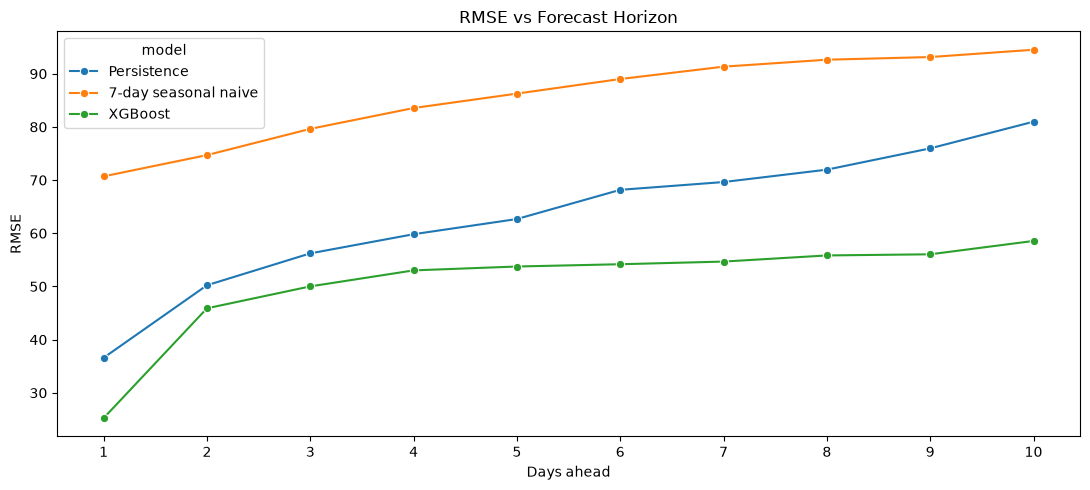

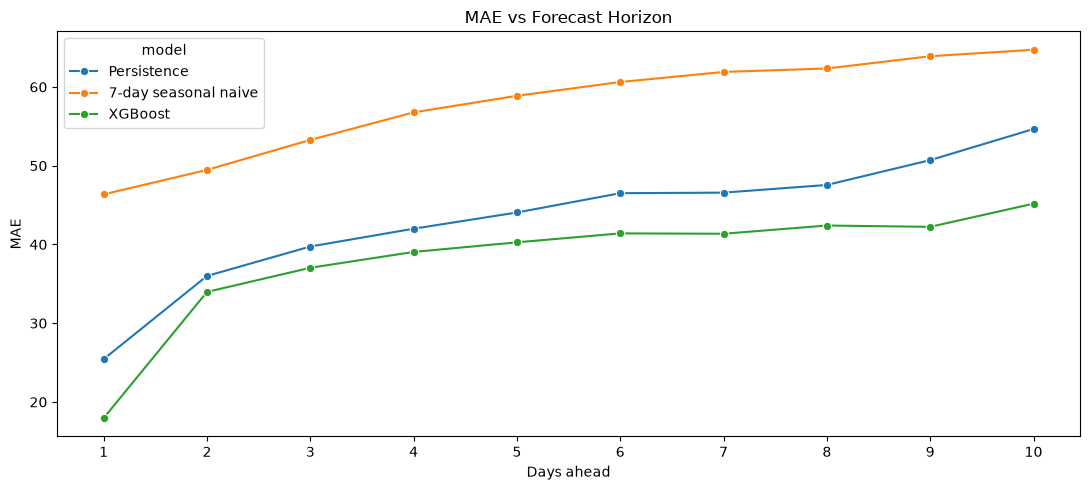

In [9]:
all_results = pd.concat([
    baseline_results,
    metrics_xgb
], ignore_index=True)

display(all_results.sort_values(["horizon", "RMSE"]))

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=all_results,
    x="horizon",
    y="RMSE",
    hue="model",
    marker="o"
)
plt.title("RMSE vs Forecast Horizon")
plt.xlabel("Days ahead")
plt.ylabel("RMSE")
plt.xticks(range(1, FORECAST_HORIZON + 1))
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=all_results,
    x="horizon",
    y="MAE",
    hue="model",
    marker="o"
)
plt.title("MAE vs Forecast Horizon")
plt.xlabel("Days ahead")
plt.ylabel("MAE")
plt.xticks(range(1, FORECAST_HORIZON + 1))
plt.tight_layout()
plt.show()


# 8. SARIMAX — classical time-series benchmark

For the classical model, we use a **single Delhi-wide daily AQI series** by default.

`SARIMAX` is useful because it captures:

- autoregression
- differencing
- moving-average behavior
- weekly seasonality

### Important limitation for 10-day forecasting

Future exogenous variables are not known unless you have weather/pollution forecasts. Therefore the cleanest classical benchmark here is a **univariate SARIMAX/SARIMA-style forecast**.

For a production SARIMAX with exogenous weather, provide a 10-day weather forecast as `future_exog`.


In [10]:
# Create Delhi-wide daily series for classical forecasting.
# Mean across available stations for each day.
city_daily = (
    daily.groupby("date")["AQI"]
         .mean()
         .sort_index()
         .dropna()
)

print(city_daily.head())
print(city_daily.tail())

# Train/test split aligned to the global cutoff.
train_series = city_daily[city_daily.index < cutoff]
test_series = city_daily[city_daily.index >= cutoff]

print("SARIMAX train:", train_series.index.min(), "to", train_series.index.max())
print("SARIMAX test:", test_series.index.min(), "to", test_series.index.max())


date
2022-01-01    399.810680
2022-01-02    419.691521
2022-01-03    410.085325
2022-01-04    407.074224
2022-01-05    409.797320
Name: AQI, dtype: float64
date
2025-12-27    394.877902
2025-12-28    409.137086
2025-12-29    413.502635
2025-12-30    402.400080
2025-12-31    408.394411
Name: AQI, dtype: float64
SARIMAX train: 2022-01-01 00:00:00 to 2025-07-03 00:00:00
SARIMAX test: 2025-07-04 00:00:00 to 2025-12-31 00:00:00


c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


SARIMAX test metrics:


,model,MAE,RMSE,R2
0,SARIMAX,164.029204,218.589933,-1.614553


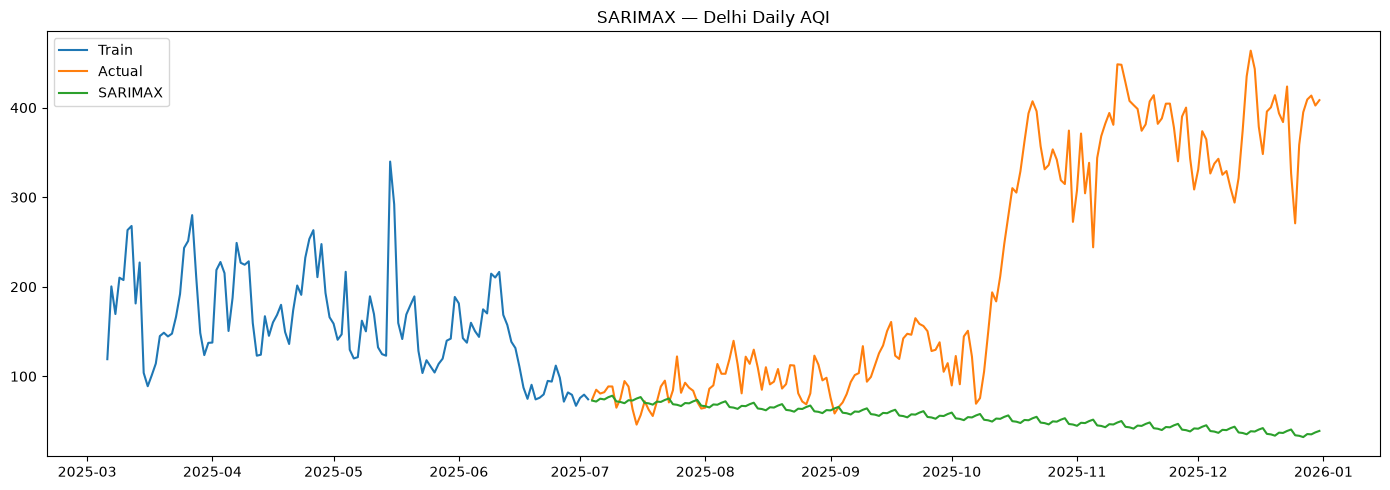

In [11]:
# SARIMAX configuration.
# Weekly seasonality is represented by seasonal period 7 for daily data.
SARIMAX_ORDER = (1, 1, 1)
SARIMAX_SEASONAL_ORDER = (1, 1, 1, 7)

sarimax_model = SARIMAX(
    train_series,
    order=SARIMAX_ORDER,
    seasonal_order=SARIMAX_SEASONAL_ORDER,
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(disp=False)

sarimax_pred = sarimax_fit.get_forecast(
    steps=len(test_series)
).predicted_mean

sarimax_score = evaluate(test_series, sarimax_pred)

print("SARIMAX test metrics:")
display(pd.DataFrame([{
    "model": "SARIMAX",
    **sarimax_score
}]))

plt.figure(figsize=(14, 5))
plt.plot(train_series.tail(120), label="Train")
plt.plot(test_series, label="Actual")
plt.plot(sarimax_pred, label="SARIMAX")
plt.title("SARIMAX — Delhi Daily AQI")
plt.legend()
plt.tight_layout()
plt.show()


# 9. 10-day SARIMAX rolling-origin evaluation

A single long test forecast is useful, but for a deployment-style question — *"if I make a forecast today, how well does it predict the next 10 days?"* — rolling-origin evaluation is better.

The function below repeatedly:

1. trains on data available up to an origin,
2. forecasts the next 10 days,
3. compares those forecasts with reality.

This is slower than one fit, so the number of origins can be limited.


In [12]:
def rolling_sarimax_backtest(series, order=(1,1,1), seasonal_order=(1,1,1,7),
                           horizon=10, origins=12):
    series = series.dropna().sort_index()
    last_possible_origin = len(series) - horizon
    origin_positions = np.linspace(
        max(60, last_possible_origin - origins + 1),
        last_possible_origin,
        num=min(origins, last_possible_origin - 59),
        dtype=int
    )

    rows = []

    for pos in origin_positions:
        train = series.iloc[:pos]
        actual = series.iloc[pos:pos+horizon]

        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fit = model.fit(disp=False)
        pred = fit.get_forecast(steps=horizon).predicted_mean

        for h, (idx, y, p) in enumerate(zip(actual.index, actual.values, pred.values), start=1):
            rows.append({
                "origin": train.index[-1],
                "date": idx,
                "horizon": h,
                "actual": y,
                "prediction": p
            })

    return pd.DataFrame(rows)

# Reduce origins if runtime is high.
sarimax_bt = rolling_sarimax_backtest(
    city_daily,
    order=SARIMAX_ORDER,
    seasonal_order=SARIMAX_SEASONAL_ORDER,
    horizon=FORECAST_HORIZON,
    origins=12
)

sarimax_bt_metrics = (
    sarimax_bt.groupby("horizon")
    .apply(lambda g: pd.Series(evaluate(g["actual"], g["prediction"])))
    .reset_index()
)
sarimax_bt_metrics["model"] = "SARIMAX rolling"
display(sarimax_bt_metrics)


c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\st

,horizon,MAE,RMSE,R2,model
0,1,30.273406,36.365222,0.091061,SARIMAX rolling
1,2,48.073943,57.097944,-2.316448,SARIMAX rolling
2,3,50.484675,65.765969,-2.097645,SARIMAX rolling
3,4,51.034992,68.557470,-0.870293,SARIMAX rolling
4,5,39.831319,56.599082,-0.592481,SARIMAX rolling
5,6,35.857817,47.175143,-0.336803,SARIMAX rolling
6,7,36.427759,46.083324,-0.207297,SARIMAX rolling
7,8,39.434493,48.060250,-0.300873,SARIMAX rolling
8,9,39.870597,51.928125,-0.502874,SARIMAX rolling
9,10,45.151205,56.032505,-0.722294,SARIMAX rolling


# 10. VARIMA-style multivariate model

### Why VAR?

AQI is not an isolated time series. Pollution variables interact.

A multivariate model can learn dynamics among:

- AQI
- PM2.5 history
- PM10 history
- NO2 history

### Why "VARIMA-style"?

`statsmodels` provides `VAR`, but not a direct high-level `VARIMA` estimator like SARIMAX.

We therefore:
1. take a multivariate daily series,
2. difference it once,
3. fit VAR on the differenced series,
4. forecast differences,
5. invert the differences to recover the level forecast.

This is a practical **VARIMA(·,1,·)-style** implementation.

> For a mathematically exact pollutant VARIMA model, use the original pollutant columns in the raw/daily dataset. The uploaded feature dataset contains pollutant history columns (`PM25_lag_1d`, etc.) rather than the contemporaneous raw pollutant measurements.


In [13]:
# Build a multivariate daily series using available historical pollutant signals.
# These are the strongest pollutant-history variables available in this uploaded file.
var_cols = [
    "AQI",
    "PM25_lag_1d",
    "PM10_lag_1d",
    "NO2_lag_1d"
]
var_cols = [c for c in var_cols if c in daily.columns]

var_daily = (daily.groupby("date")[var_cols].mean().sort_index().dropna())

print("VAR variables:", var_cols)
display(var_daily.describe().T)


VAR variables: ['AQI', 'PM25_lag_1d', 'PM10_lag_1d', 'NO2_lag_1d']


,count,mean,std,min,25%,50%,75%,max
AQI,1460.0,218.052707,110.711371,42.721703,120.043147,195.227709,314.149796,486.412141
PM25_lag_1d,1460.0,104.453531,77.903572,12.311168,45.531882,78.335739,143.011260,553.634076
PM10_lag_1d,1460.0,214.732963,110.078315,23.065532,125.511628,202.100545,287.763271,695.743095
NO2_lag_1d,1460.0,48.730863,21.832697,8.974250,34.237657,43.696158,58.528253,162.684452


Selected/used VAR lag: 7
VARIMA-style AQI metrics:


c:\Users\haris\OneDrive\Documents\airguard\airguard\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,model,MAE,RMSE,R2
0,VARIMA-style,271.736731,305.033136,-4.091329


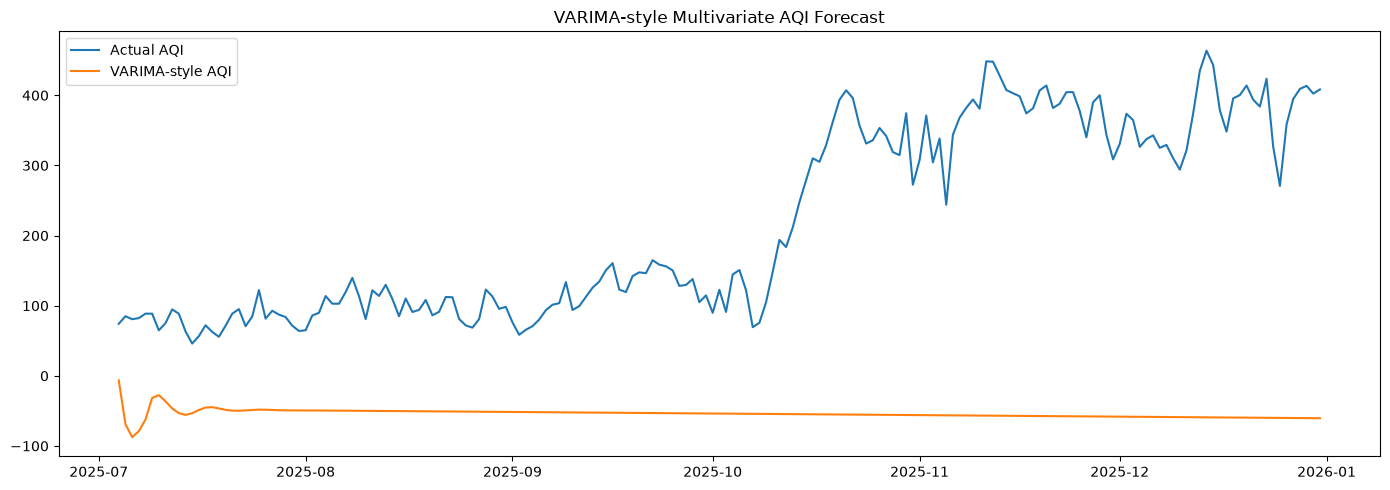

In [14]:
# Chronological split
var_train = var_daily[var_daily.index < cutoff]
var_test = var_daily[var_daily.index >= cutoff]

# Difference once = I(1) component.
var_diff = var_train.diff().dropna()

# Choose a small lag order to avoid parameter explosion.
VAR_LAGS = 7

var_model = VAR(var_diff)

# Use a modest lag. You can inspect select_order separately if desired.
var_fit = var_model.fit(maxlags=VAR_LAGS, ic=None, trend="c")

print("Selected/used VAR lag:", var_fit.k_ar)

# Forecast differences for the entire test period.
last_values = var_train.values[-var_fit.k_ar:]
diff_forecast = var_fit.forecast(
    y=last_values,
    steps=len(var_test)
)

# Integrate differences back to levels.
last_level = var_train.iloc[-1].values
level_forecast = np.cumsum(diff_forecast, axis=0) + last_level

var_pred_df = pd.DataFrame(
    level_forecast,
    index=var_test.index,
    columns=var_cols
)

var_score = evaluate(var_test["AQI"], var_pred_df["AQI"])

print("VARIMA-style AQI metrics:")
display(pd.DataFrame([{
    "model": "VARIMA-style",
    **var_score
}]))

plt.figure(figsize=(14, 5))
plt.plot(var_test.index, var_test["AQI"], label="Actual AQI")
plt.plot(var_pred_df.index, var_pred_df["AQI"], label="VARIMA-style AQI")
plt.title("VARIMA-style Multivariate AQI Forecast")
plt.legend()
plt.tight_layout()
plt.show()


# 11. Compare all model families

The comparison should answer:

> Does a sophisticated ML model actually beat persistence and classical time-series forecasting at different forecast horizons?


In [15]:
# Add SARIMAX and VARIMA-style summary rows.
classical_summary = pd.DataFrame([
    {"model": "SARIMAX", "horizon": FORECAST_HORIZON, **sarimax_score},
    {"model": "VARIMA-style", "horizon": FORECAST_HORIZON, **var_score}
])

comparison = pd.concat(
    [all_results, classical_summary],
    ignore_index=True
)

display(comparison.sort_values(["horizon", "RMSE"]))


,model,horizon,MAE,RMSE,R2
20,XGBoost,1,17.950205,25.251171,0.967878
0,Persistence,1,25.438471,36.594668,0.932597
1,7-day seasonal naive,1,46.360852,70.702095,0.747675
21,XGBoost,2,33.969779,45.893784,0.893848
2,Persistence,2,35.994998,50.226565,0.872819
3,7-day seasonal naive,2,49.462349,74.697547,0.718287
22,XGBoost,3,37.035008,50.013463,0.873826
4,Persistence,3,39.737392,56.221476,0.840147
5,7-day seasonal naive,3,53.272521,79.631088,0.679547
23,XGBoost,4,39.046492,53.021272,0.858095


# 12. SHAP explainability for XGBoost

SHAP tells us how each feature moves an individual prediction away from the model's baseline.

For example:

- positive SHAP for `PM25_lag_1d` → pushes predicted AQI upward
- negative SHAP for `wind_speed` → pushes predicted AQI downward

### Important interpretation distinction

This is **predictive contribution**, not causal contribution.

Because AQI itself is derived from pollutant concentrations, an AQI-history feature can dominate the model. Therefore the notebook reports:

1. raw feature-level SHAP
2. grouped SHAP by feature family


SHAP sample shape: (817, 114)


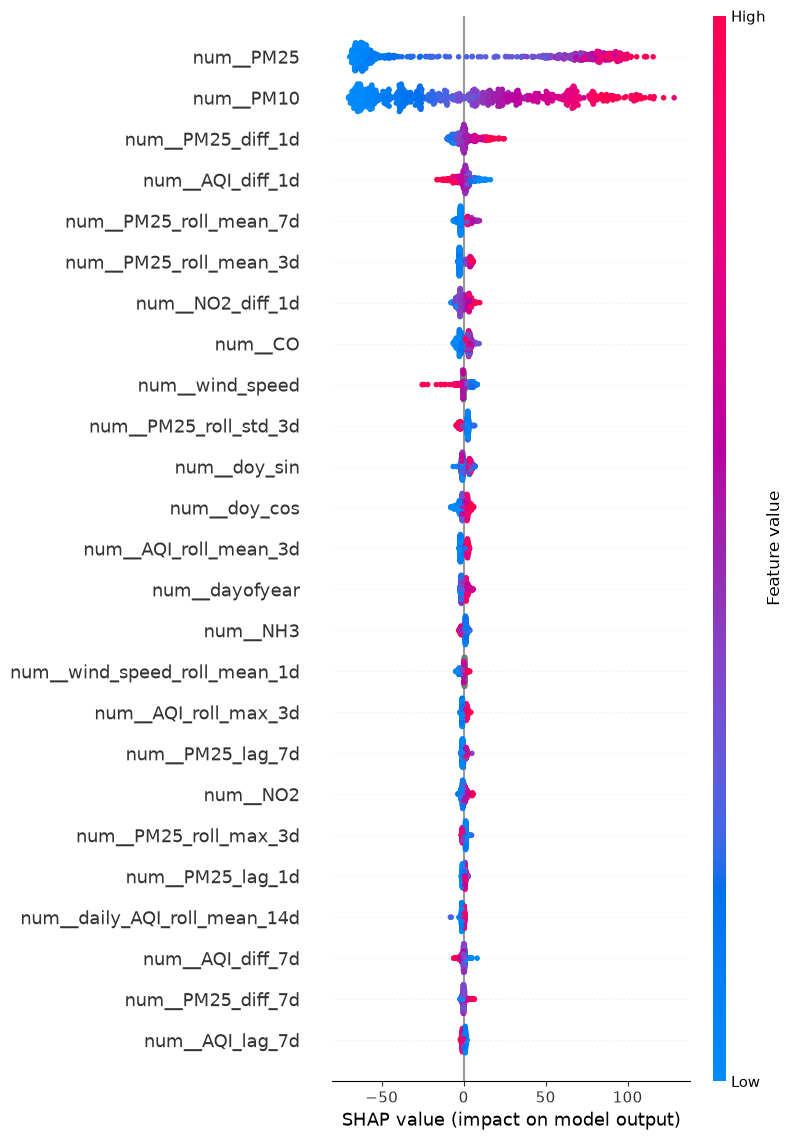

In [ ]:
# Explain the 1-day-ahead model first.
model_h1 = models[1]

# Transform a sample of test observations.
valid_h1 = test_mask & daily["target_h1"].notna()
X_h1 = X.loc[valid_h1].copy()
# Access the fitted preprocessing and XGBoost estimator.
prep = model_h1.named_steps["prep"]
xgb = model_h1.named_steps["model"]

X_trans = prep.transform(X_h1)

# Get transformed feature names.
feature_names_trans = prep.get_feature_names_out()

# SHAP on a manageable sample.
sample_n = min(3000, len(X_trans))
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_trans), size=sample_n, replace=False)

X_shap = X_trans[sample_idx]
X_shap_df = pd.DataFrame(X_shap, columns=feature_names_trans)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_shap_df)

print("SHAP sample shape:", np.asarray(shap_values).shape)

shap.summary_plot(
    shap_values,
    X_shap_df,
    max_display=25,
    show=True
)


In [17]:
# Mean absolute SHAP importance
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = (
    pd.DataFrame({
        "feature": feature_names_trans,
        "mean_abs_shap": mean_abs_shap
    })
    .sort_values("mean_abs_shap", ascending=False)
)

display(shap_importance.head(30))


,feature,mean_abs_shap
77,num__PM25,66.344391
78,num__PM10,44.148872
73,num__PM25_diff_1d,4.663716
22,num__AQI_diff_1d,3.309105
58,num__PM25_roll_mean_7d,2.938390
57,num__PM25_roll_mean_3d,2.883706
75,num__NO2_diff_1d,2.811404
81,num__CO,2.669911
86,num__wind_speed,2.653801
61,num__PM25_roll_std_3d,2.338575


## 13. Group SHAP into human-readable pollutant/weather/calendar families

This is more useful for your project presentation than a raw list of 100 features.

The groups are:

- **AQI history**
- **PM2.5 history**
- **PM10 history**
- **NO2 history**
- **Weather**
- **Calendar**
- **Station**
- **Other**

A high PM2.5 group score means historical PM2.5-related features collectively influenced predictions strongly.


,group,mean_abs_shap
0,PM2.5 history,87.439995
1,PM10 history,46.348373
2,AQI history,19.191679
3,Weather,8.474577
4,Calendar,7.540535
5,NO2 history,5.506315
6,Other,5.335742
7,Station,0.114999


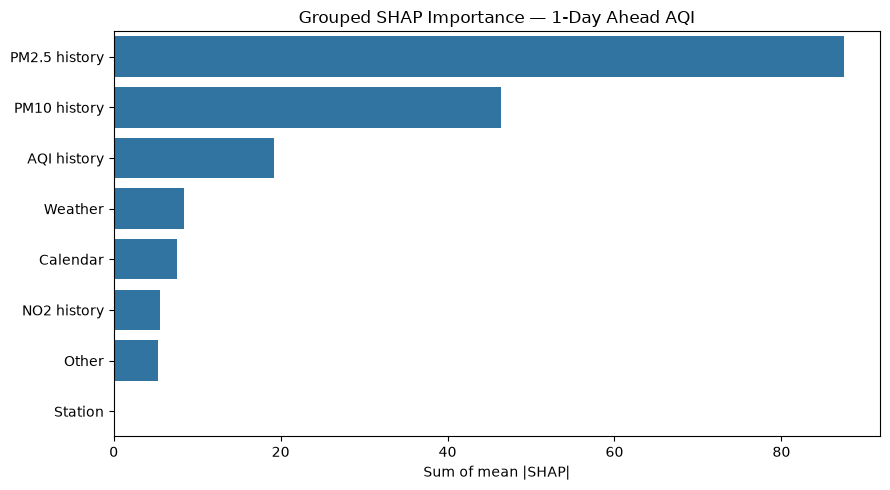

In [18]:
def shap_group(feature):
    f = feature.lower()

    if "pm25" in f:
        return "PM2.5 history"
    if "pm10" in f:
        return "PM10 history"
    if "no2" in f:
        return "NO2 history"
    if "aqi" in f:
        return "AQI history"
    if any(x in f for x in [
        "temperature", "humidity", "wind", "pressure",
        "solar", "rainfall"
    ]):
        return "Weather"
    if any(x in f for x in [
        "month", "day", "dow", "doy", "weekend",
        "season", "hour", "calendar"
    ]):
        return "Calendar"
    if "station" in f:
        return "Station"
    return "Other"

shap_importance["group"] = shap_importance["feature"].map(shap_group)

group_shap = (
    shap_importance.groupby("group")["mean_abs_shap"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(group_shap)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=group_shap,
    x="mean_abs_shap",
    y="group"
)
plt.title("Grouped SHAP Importance — 1-Day Ahead AQI")
plt.xlabel("Sum of mean |SHAP|")
plt.ylabel("")
plt.tight_layout()
plt.show()


# 14. Local explanation: why did the model make this forecast?

Pick one test date/station and inspect the features pushing the prediction up/down.

This is useful for your deployment UI:

> **Tomorrow's AQI forecast: 342**
>
> Main upward drivers:
> - high recent PM2.5
> - high AQI persistence
> - high recent PM10
>
> Main downward drivers:
> - stronger wind
> - lower recent AQI trend


Largest downward drivers:


,feature,value,shap
77,num__PM25,28.958333,-64.518623
78,num__PM10,74.250000,-56.032825
106,num__doy_cos,-0.999166,-4.947349
57,num__PM25_roll_mean_3d,25.987269,-2.626473
6,num__AQI_roll_mean_3d,78.548074,-2.156239
82,num__O3,4.049048,-2.031045
58,num__PM25_roll_mean_7d,29.450349,-1.837618
103,num__dayofyear,185.000000,-1.501197
79,num__NO2,35.549167,-1.404246
81,num__CO,1.074583,-1.307780


Largest upward drivers:


,feature,value,shap
61,num__PM25_roll_std_3d,8.808578,2.596206
75,num__NO2_diff_1d,6.004167,2.451653
69,num__PM25_roll_max_3d,52.958333,2.221995
92,num__wind_speed_lag_1d,1.377083,1.593769
97,num__wind_speed_roll_mean_1d,1.088299,1.548487
83,num__NH3,21.755417,1.351800
86,num__wind_speed,0.660000,1.143485
22,num__AQI_diff_1d,1.000868,1.022976
3,num__AQI_lag_7d,72.019097,0.890145
47,num__PM10_lag_2d,88.541667,0.629897


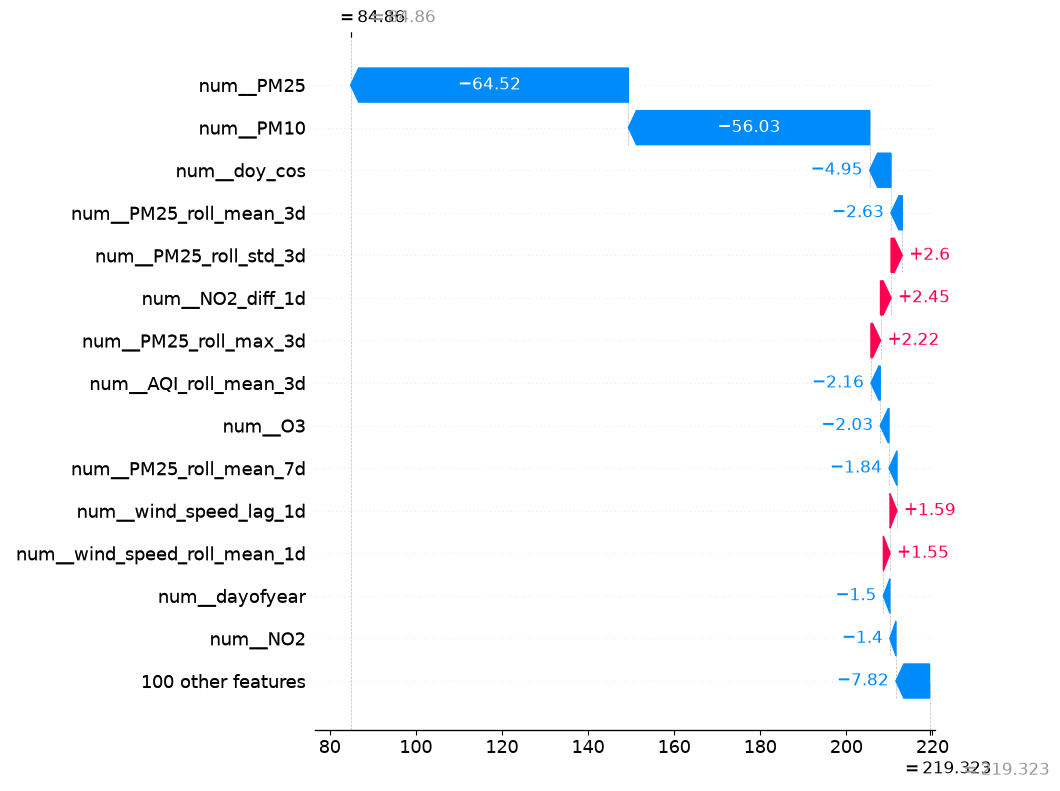

In [19]:
# Select a single example from the 1-day test set.
example_pos = 0
example_row = X_h1.iloc[[example_pos]]

example_trans = prep.transform(example_row)
example_trans_df = pd.DataFrame(example_trans, columns=feature_names_trans)

example_shap = explainer.shap_values(example_trans_df)[0]

local = (
    pd.DataFrame({
        "feature": feature_names_trans,
        "value": example_trans_df.iloc[0].values,
        "shap": example_shap
    })
    .sort_values("shap")
)

print("Largest downward drivers:")
display(local.head(10))

print("Largest upward drivers:")
display(local.tail(10).sort_values("shap", ascending=False))

shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value,
    example_shap,
    feature_names=feature_names_trans,
    features=example_trans_df.iloc[0].values,
    max_display=15,
    show=True
)


# 15. Feature importance by pollutant/factor

SHAP is the main explanation method. This additional table converts the result into something suitable for your report/resume.

### Interpretation

- **AQI history** = persistence/memory of pollution
- **PM2.5 history** = particulate pollution signal
- **PM10 history** = coarse particulate signal
- **NO2 history** = traffic/combustion-related signal
- **Weather** = atmospheric dispersion/meteorological conditions
- **Calendar** = seasonal/weekly structure

Again, this is predictive importance, **not causal attribution**.


In [20]:
# Normalized group contribution
group_shap["relative_%"] = (
    100 * group_shap["mean_abs_shap"] /
    group_shap["mean_abs_shap"].sum()
)

display(group_shap)


,group,mean_abs_shap,relative_%
0,PM2.5 history,87.439995,48.590672
1,PM10 history,46.348373,25.755936
2,AQI history,19.191679,10.664875
3,Weather,8.474577,4.709349
4,Calendar,7.540535,4.190299
5,NO2 history,5.506315,3.059876
6,Other,5.335742,2.965088
7,Station,0.114999,0.063906


# 16. 10-day forecast from the latest available data

For XGBoost, we use the latest row available for each station and predict horizons 1–10.

Because these are direct horizon-specific models, each horizon has its own trained model.

For a production API, you would:
1. load the latest cleaned observations,
2. regenerate exactly the same feature pipeline,
3. pass the latest feature row to models 1–10,
4. return the 10 predicted AQI values.


,forecast_date,horizon_days,predicted_AQI
0,2026-01-01,1,385.794067
1,2026-01-02,2,382.334412
2,2026-01-03,3,385.648895
3,2026-01-04,4,393.856934
4,2026-01-05,5,383.378510
5,2026-01-06,6,375.149597
6,2026-01-07,7,359.736755
7,2026-01-08,8,342.188171
8,2026-01-09,9,364.875275
9,2026-01-10,10,358.869171


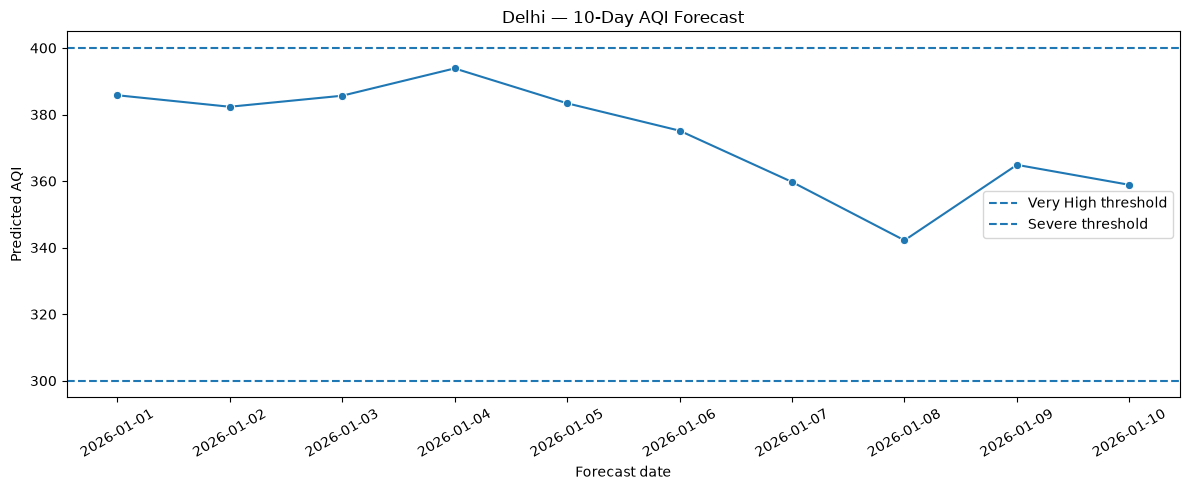

In [21]:
latest_rows = (
    daily.sort_values("date")
         .groupby("station", as_index=False)
         .tail(1)
         .copy()
)

future_predictions = []

for h, model in models.items():
    X_latest = latest_rows[feature_cols + ["station"]]
    pred = model.predict(X_latest)

    temp = latest_rows[["station", "date"]].copy()
    temp["horizon_days"] = h
    temp["forecast_date"] = temp["date"] + pd.to_timedelta(h, unit="D")
    temp["predicted_AQI"] = pred
    future_predictions.append(temp)

forecast_10d = pd.concat(future_predictions, ignore_index=True)

# Display Delhi-wide average across stations.
forecast_city = (
    forecast_10d.groupby(
        ["forecast_date", "horizon_days"], as_index=False
    )["predicted_AQI"].mean()
    .sort_values("forecast_date")
)

display(forecast_city)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=forecast_city,
    x="forecast_date",
    y="predicted_AQI",
    marker="o"
)
plt.axhline(300, linestyle="--", label="Very High threshold")
plt.axhline(400, linestyle="--", label="Severe threshold")
plt.title("Delhi — 10-Day AQI Forecast")
plt.xlabel("Forecast date")
plt.ylabel("Predicted AQI")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 17. Forecast uncertainty — recommended extension

Point forecasts alone are not enough for a serious forecasting application.

For SARIMAX, confidence intervals are available directly:

```python
forecast = fitted_model.get_forecast(steps=10)
forecast.summary_frame()
```

For XGBoost, you can estimate uncertainty using:

- quantile models
- conformal prediction
- bootstrap/ensemble dispersion

A strong production version should return:

`predicted AQI + lower bound + upper bound`

rather than only one number.


# 18. Recommended final project architecture

```text
CPCB hourly data
      │
      ▼
Data cleaning + AQI construction
      │
      ▼
Feature engineering
      │
      ├── Calendar + cyclic
      ├── AQI lags
      ├── Pollutant lags
      ├── Rolling statistics
      ├── Trend/deviation
      └── Weather history
      │
      ▼
Daily forecasting dataset
      │
      ├───────────────┬─────────────────┐
      ▼               ▼                 ▼
 Persistence       SARIMAX        VARIMA-style
      │               │                 │
      └───────────────┴─────────────────┘
                      │
                      ▼
                 XGBoost
              10 direct models
                      │
                      ▼
              10-day forecast
                      │
              ┌───────┴────────┐
              ▼                ▼
           SHAP            uncertainty
              │
              ▼
      "Why is AQI expected
          to increase?"
```

## What to report

At minimum, report:

- MAE by horizon
- RMSE by horizon
- R² by horizon
- persistence vs ML improvement
- SARIMAX vs XGBoost
- VARIMA-style vs XGBoost
- station-wise performance
- SHAP global importance
- grouped pollutant/weather contribution
- one local SHAP explanation
- 10-day forecast visualization

### Critical limitation to address in the final report

The uploaded feature dataset contains **historical pollutant features**, but not the original contemporaneous `PM25`, `PM10`, `NO2`, etc. columns. Therefore:

- SHAP can explain the predictive contribution of **pollutant history**.
- A true contemporaneous pollutant contribution analysis requires adding the original pollutant measurements back into the daily dataset.
- A true exogenous SARIMAX 10-day forecast requires future exogenous inputs (e.g. weather forecasts).
- The VARIMA section is explicitly a **VAR on differenced multivariate signals**, used as a practical VARIMA-style benchmark.
